In [2]:
import random
import numpy as np

import matplotlib.pyplot as plt


def generate_random_value():
    return random.randint(0, 1)

def create_individual(n):
    return [generate_random_value() for _ in range(n)]

def compute_fitness(individual):
    return sum(individual)

def selection(population):
    individual1, individual2 = random.sample(population, 2)
    if compute_fitness(individual1) > compute_fitness(individual2):
        return individual1
    return individual2

def crossover(parent1, parent2, rate = 0.9):
    child1 = parent1.copy()
    child2 = parent2.copy()
    if random.random() < rate:
        for i in range(len(parent1)):
            if random.random() < 0.5:
                child1[i], child2[i] = child2[i], child1[i]
    return child1, child2

def mutation(individual, rate = 0.05):
    return [1 - value if random.random() < rate else value for value in individual]

In [27]:
n = 100
m = 100
generations = 100
elitism = 2
population = [create_individual(n) for _ in range(m)]
fitness_history = []
for gen in range(generations):
    population = sorted(population, key = compute_fitness, reverse=True)
    parent1 = selection(population)
    parent2 = selection(population)

    if gen % 10 == 0:
        best_individual = population[0]
        best_fitness = compute_fitness(best_individual)
        fitness_history.append(best_fitness)

    new_population = population[:elitism]
    while len(new_population) < m:

        child1, child2 = crossover(parent1, parent2)
        new_population.append(mutation(child1))

        if len(new_population) < m:
            new_population.append(mutation(child2))
    population = new_population

best_individual = sorted(population, key = compute_fitness, reverse=True)[0]
best_fitness = compute_fitness(best_individual)
print(f'Best Individual: {best_individual}')
print(f'Best fitness: {best_fitness}')

Best Individual: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1]
Best fitness: 88


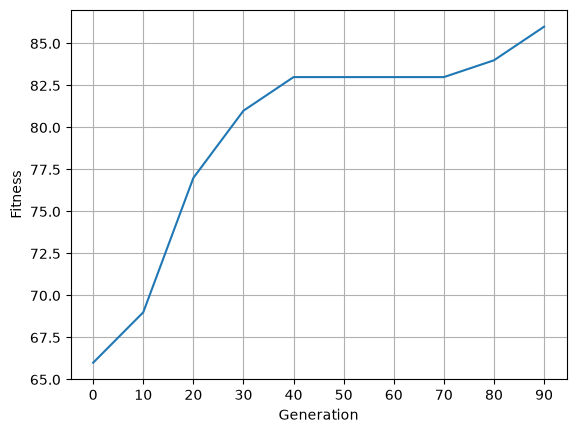

In [28]:
plt.plot(fitness_history)
plt.xlabel('Generation')
plt.ylabel('Fitness')
plt.xticks(ticks=range(0, len(fitness_history), 1), labels=[str(i * 10) for i in range(len(fitness_history))])
plt.grid()
plt.show()